# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Стасюк Дарья Васильевна
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, HTML, display
def n(x): return f"{int(x):,}".replace(",", " ")
display(HTML("<style>body, .jp-RenderedHTMLCommon {font-size: 12.5px; line-height: 1.4} h2 {margin-top: 14px} h3 {margin-top: 10px}</style>"))

sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.dpi"] = 110

clients = pd.read_parquet("clean_clients.parquet")
txn = pd.read_parquet("clean_transactions.parquet")
cm = pd.read_parquet("client_metrics.parquet")
log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv("campaign_list.csv")

BASE_END = pd.Timestamp("2025-01-01")
DROP = -0.30
GROUP_NAMES = {
    "G1_mass_noapp_fadeout": "G1. Массовый без приложения: активность сошла почти на нет",
    "G2_mass_app_broad_drop": "G2. Массовый с приложением: падение по всем категориям",
    "G3_nonmass_clothes_stop": "G3. Зарплатный/Премиальный/Private: перестали покупать одежду",
}
pur = txn[txn["in_directory"] & (txn["status"] == "успешно")].merge(
    clients[["client_id", "segment", "has_mobile_app"]], on="client_id")
pur["period"] = np.where(pur["txn_datetime"] < BASE_END, "base", "eval")
pur["month"] = pur["txn_datetime"].dt.to_period("M")

def yoy(df, by):
    t = df.groupby(by + ["period"]).size().unstack("period")
    return ((t["eval"] / 6) / (t["base"] / 12) - 1) * 100

v = cm[cm["rate_base"].notna() & (cm["rate_base"] > 0)]
seg_app = v.groupby(["segment", "has_mobile_app"])["change"].median() * 100
seg = v.groupby("segment")["change"].median() * 100
camp = cm[cm["group"].notna()]
gsum = camp.groupby("group").agg(n=("client_id", "size"), chg=("change", "median"), chg_oth=("change_other", "median"),
                                 rb=("rate_base", "median"), re=("rate_eval", "median"), last2=("last2_to_base", "median"),
                                 cb=("rate_base_clothes", "median"), ce=("rate_eval_clothes", "median"))
h1 = pur[(pur["txn_datetime"] < "2024-07-01")].groupby("segment").size()
h2 = pur[(pur["txn_datetime"] >= "2025-01-01")].groupby("segment").size()
yoy_seg = (h2 / h1 - 1) * 100
cat_seg = yoy(pur, ["segment", "category"]).unstack()
clothes_nonmass = cat_seg.drop(index="Массовый")["Одежда и обувь"]
other_nonmass = cat_seg.drop(index="Массовый").drop(columns="Одежда и обувь")
ch = yoy(pur, ["channel"])
n_noconsent_drop = int((~cm["marketing_opt_in"] & (cm["change"] <= DROP)).sum())

## 1. Главное

In [2]:
g = gsum
display(Markdown(f'''
1. **В кампанию предлагается {len(campaign)} клиентов в трёх группах** (бюджет — 2000): {g.loc["G1_mass_noapp_fadeout","n"]}, {g.loc["G2_mass_app_broad_drop","n"]} и {g.loc["G3_nonmass_clothes_stop","n"]} человек. У каждой группы своя причина падения, поэтому и предложение нужно разное.
2. **Падение сосредоточено в массовом сегменте.** Медианный клиент массового сегмента в январе–июне 2025 г. совершает на {abs(seg["Массовый"]):.0f}% меньше покупок в месяц, чем в 2024 г.; без мобильного приложения — на {abs(seg_app[("Массовый", False)]):.0f}%. В остальных сегментах снижение {abs(seg.drop("Массовый")).min():.0f}–{abs(seg.drop("Массовый")).max():.0f}%, и оно почти целиком объясняется сезонностью.
3. **Во всех сегментах падают покупки одежды и обуви:** у немассовых клиентов на {abs(clothes_nonmass).min():.0f}–{abs(clothes_nonmass).max():.0f}% при изменении остальных категорий от {other_nonmass.min().min():+.0f}% до {other_nonmass.max().max():+.0f}%.
4. **Рост оплаты телефоном — не потеря клиентов.** Покупки пластиковой картой снизились на {abs(ch["Карта"]):.0f}%, а через токен выросли на {ch["Токен"]:.0f}%: клиенты сменили способ оплаты.
5. **{n_noconsent_drop} клиентов с сильным падением не могут войти в кампанию** из-за отсутствия согласия на коммуникацию.

Все изменения — среднемесячное число успешных покупок за январь–июнь 2025 г. к среднемесячному за 2024 г.
'''))


1. **В кампанию предлагается 1343 клиентов в трёх группах** (бюджет — 2000): 507, 573 и 263 человек. У каждой группы своя причина падения, поэтому и предложение нужно разное.
2. **Падение сосредоточено в массовом сегменте.** Медианный клиент массового сегмента в январе–июне 2025 г. совершает на 35% меньше покупок в месяц, чем в 2024 г.; без мобильного приложения — на 56%. В остальных сегментах снижение 10–14%, и оно почти целиком объясняется сезонностью.
3. **Во всех сегментах падают покупки одежды и обуви:** у немассовых клиентов на 18–35% при изменении остальных категорий от -14% до +3%.
4. **Рост оплаты телефоном — не потеря клиентов.** Покупки пластиковой картой снизились на 28%, а через токен выросли на 32%: клиенты сменили способ оплаты.
5. **256 клиентов с сильным падением не могут войти в кампанию** из-за отсутствия согласия на коммуникацию.

Все изменения — среднемесячное число успешных покупок за январь–июнь 2025 г. к среднемесячному за 2024 г.


## 2. Контекст

За последние полгода клиенты банка реже пользуются картами. Департамент готовит кампанию по возврату
активности на 2000 клиентов и просит определить 3–5 групп по 150+ человек. Каждая группа должна быть
описана правилом по признакам клиента и иметь понятную причину падения, чтобы под неё можно было
подготовить своё предложение. Писать можно только клиентам с согласием на коммуникацию.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

In [3]:
n_cl = len(clients); n_tx = len(txn)
n_pur = len(pur); n_cl_pur = pur["client_id"].nunique()
orph = txn.loc[~txn["in_directory"], "client_id"].nunique(); orph_rows = int((~txn["in_directory"]).sum())
nonsucc = int((txn["in_directory"] & (txn["status"] != "успешно")).sum())
nobase = int(cm["rate_base"].isna().sum())
season = (pur[pur["txn_datetime"] < "2024-07-01"].shape[0] / 6) / ((pur["period"] == "base").sum() / 12) - 1
display(Markdown(f'''
**Данные.** Справочник из {n(n_cl)} действующих клиентов на 30.06.2025 и {n(n_tx)} операций по картам за
01.01.2024–30.06.2025 после очистки. Базовый период — 2024 год (12 мес.), оцениваемый — январь–июнь 2025 г. (6 мес.).

**Что исключено из расчёта.** Операции {orph} клиентов, которых нет в справочнике ({n(orph_rows)} операций):
их активность почти прекратилась к марту 2025 г., скорее всего, это ушедшие клиенты. Отклонённые операции и
возвраты ({n(nonsucc)}): это не покупки. В итоге в расчёте {n(n_pur)} покупок {n(n_cl_pur)} клиентов. Ещё {nobase} клиентов
открыли карту позже сентября 2024 г.: сравнивать им не с чем.

**Метрика активности** — число успешных покупок по карте в месяц на клиента. Считается отдельно за 2024 г. и
за январь–июнь 2025 г., каждый раз делится на число месяцев, когда у клиента была карта, затем периоды
сравниваются. Окна разной длины, поэтому сравниваются частоты, а не суммы за период. Число покупок не зависит
от валюты и крупных чеков. Сезонность (декабрьский пик, январский провал) сама даёт около {season:+.0%},
поэтому падением считается снижение на 30% и больше. **Метрика не видит**: уменьшения сумм при том же числе
покупок; переноса части трат в другой банк или на наличные, если число операций не изменилось; временных
провалов, которые восстановились внутри полугодия; клиентов, ушедших из банка.

**Чего нет в данных:** курсов валют (0,4% операций не в рублях), причин отказов, остатков и операций по
другим продуктам, трат клиентов в других банках, истории сегмента и приложения (только состояние на дату
среза), времени у 8% операций, оценки качества у 59% клиентов.
'''))


**Данные.** Справочник из 5 674 действующих клиентов на 30.06.2025 и 621 194 операций по картам за
01.01.2024–30.06.2025 после очистки. Базовый период — 2024 год (12 мес.), оцениваемый — январь–июнь 2025 г. (6 мес.).

**Что исключено из расчёта.** Операции 326 клиентов, которых нет в справочнике (26 136 операций):
их активность почти прекратилась к марту 2025 г., скорее всего, это ушедшие клиенты. Отклонённые операции и
возвраты (19 020): это не покупки. В итоге в расчёте 576 038 покупок 5 665 клиентов. Ещё 540 клиентов
открыли карту позже сентября 2024 г.: сравнивать им не с чем.

**Метрика активности** — число успешных покупок по карте в месяц на клиента. Считается отдельно за 2024 г. и
за январь–июнь 2025 г., каждый раз делится на число месяцев, когда у клиента была карта, затем периоды
сравниваются. Окна разной длины, поэтому сравниваются частоты, а не суммы за период. Число покупок не зависит
от валюты и крупных чеков. Сезонность (декабрьский пик, январский провал) сама даёт около -7%,
поэтому падением считается снижение на 30% и больше. **Метрика не видит**: уменьшения сумм при том же числе
покупок; переноса части трат в другой банк или на наличные, если число операций не изменилось; временных
провалов, которые восстановились внутри полугодия; клиентов, ушедших из банка.

**Чего нет в данных:** курсов валют (0,4% операций не в рублях), причин отказов, остатков и операций по
другим продуктам, трат клиентов в других банках, истории сегмента и приложения (только состояние на дату
среза), времени у 8% операций, оценки качества у 59% клиентов.


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Падение сосредоточено в массовом сегменте, сильнее всего — у клиентов без приложения

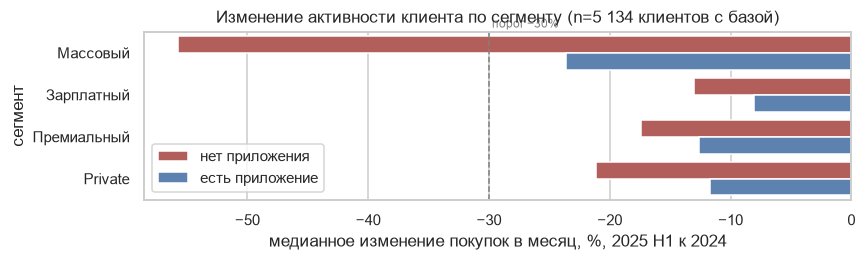

В массовом сегменте (2 646 клиентов) медианное снижение 35%, у клиентов
без приложения 56%. Год к году (январь–июнь 2025 к январю–июню 2024) массовый сегмент потерял
26% покупок, а остальные сегменты изменились в пределах -0.4…+1.2%: их снижение к 2024 г.
в целом — сезонный эффект.

In [4]:
display(Markdown(f"### 4.1. Падение сосредоточено в массовом сегменте, сильнее всего — у клиентов без приложения"))
fig, ax = plt.subplots(figsize=(8, 2.5))
d = seg_app.rename("изменение").reset_index()
d["приложение"] = d["has_mobile_app"].map({True: "есть приложение", False: "нет приложения"})
order = ["Массовый", "Зарплатный", "Премиальный", "Private"]
sns.barplot(data=d, y="segment", x="изменение", hue="приложение", order=order, ax=ax, palette=["#c0504d", "#4f81bd"])
ax.axvline(DROP * 100, color="grey", ls="--", lw=1); ax.text(DROP * 100, -0.6, " порог −30%", color="grey", fontsize=8)
ax.set(xlabel="медианное изменение покупок в месяц, %, 2025 H1 к 2024", ylabel="сегмент")
ax.legend(title="", loc="lower left")
counts = v.groupby(["segment", "has_mobile_app"]).size()
plt.title(f"Изменение активности клиента по сегменту (n={n(len(v))} клиентов с базой)"); plt.tight_layout(); plt.show()
display(Markdown(f'''В массовом сегменте ({n(counts["Массовый"].sum())} клиентов) медианное снижение {abs(seg["Массовый"]):.0f}%, у клиентов
без приложения {abs(seg_app[("Массовый", False)]):.0f}%. Год к году (январь–июнь 2025 к январю–июню 2024) массовый сегмент потерял
{abs(yoy_seg["Массовый"]):.0f}% покупок, а остальные сегменты изменились в пределах {yoy_seg.drop("Массовый").min():+.1f}…{yoy_seg.drop("Массовый").max():+.1f}%: их снижение к 2024 г.
в целом — сезонный эффект.'''))

### 4.2. Покупки одежды и обуви падают во всех сегментах, остальные категории — только в массовом

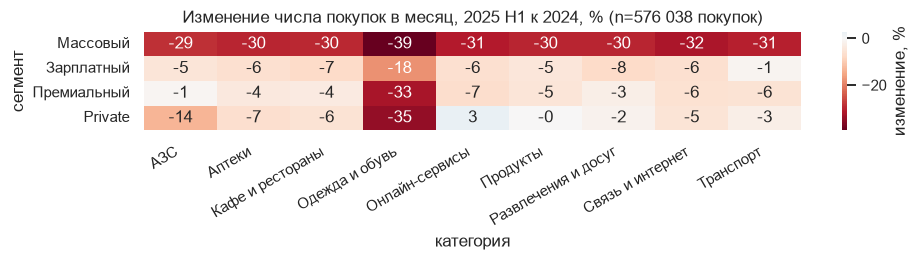

В массовом сегменте падают все девять категорий примерно одинаково (от -29 до -39%):
клиенты в целом реже пользуются картой. В других сегментах выделяется только «Одежда и обувь»
(от -18 до -35%). Это отдельная причина, связанная с категорией, а не с клиентом:
вероятно, покупки одежды ушли на другие способы оплаты или в другой банк.

In [5]:
display(Markdown("### 4.2. Покупки одежды и обуви падают во всех сегментах, остальные категории — только в массовом"))
fig, ax = plt.subplots(figsize=(9, 2.5))
sns.heatmap(cat_seg.loc[order], annot=True, fmt=".0f", cmap="RdBu", center=0, ax=ax, cbar_kws={"label": "изменение, %"})
ax.set(xlabel="категория", ylabel="сегмент",
       title=f"Изменение числа покупок в месяц, 2025 H1 к 2024, % (n={n(len(pur))} покупок)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
display(Markdown(f'''В массовом сегменте падают все девять категорий примерно одинаково (от {cat_seg.loc["Массовый"].max():.0f} до {cat_seg.loc["Массовый"].min():.0f}%):
клиенты в целом реже пользуются картой. В других сегментах выделяется только «Одежда и обувь»
(от {clothes_nonmass.max():.0f} до {clothes_nonmass.min():.0f}%). Это отдельная причина, связанная с категорией, а не с клиентом:
вероятно, покупки одежды ушли на другие способы оплаты или в другой банк.'''))

### 4.3. Пластиковую карту заменяет оплата телефоном, а провал СБП был временным

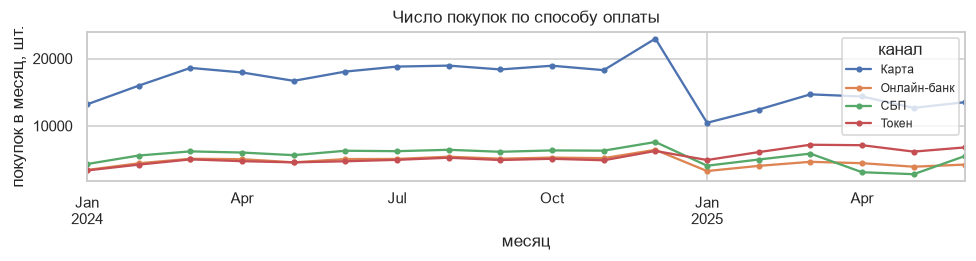

С января 2025 г. покупки пластиком упали на 28%, а через токен (телефон, часы) выросли на 32%.
Это смена способа оплаты, а не потеря клиента, поэтому таких клиентов в кампанию не берём. Покупки через СБП
в апреле–мае 2025 г. упали до 3 113 и 2 821 (в марте было 5 880),
а в июне вернулись к 5 541. Это похоже на технический сбой: причина на стороне банка, коммуникация её не исправит.

In [6]:
display(Markdown("### 4.3. Пластиковую карту заменяет оплата телефоном, а провал СБП был временным"))
chm = pur.groupby(["month", "channel"]).size().unstack()
fig, ax = plt.subplots(figsize=(9, 2.5))
chm.index = chm.index.to_timestamp()
chm.plot(ax=ax, marker=".")
ax.set(xlabel="месяц", ylabel="покупок в месяц, шт.", title="Число покупок по способу оплаты")
ax.legend(title="канал", fontsize=8); plt.tight_layout(); plt.show()
sbp = pur[pur["channel"] == "СБП"].groupby("month").size()
display(Markdown(f'''С января 2025 г. покупки пластиком упали на {abs(ch["Карта"]):.0f}%, а через токен (телефон, часы) выросли на {ch["Токен"]:.0f}%.
Это смена способа оплаты, а не потеря клиента, поэтому таких клиентов в кампанию не берём. Покупки через СБП
в апреле–мае 2025 г. упали до {n(sbp[pd.Period("2025-04","M")])} и {n(sbp[pd.Period("2025-05","M")])} (в марте было {n(sbp[pd.Period("2025-03","M")])}),
а в июне вернулись к {n(sbp[pd.Period("2025-06","M")])}. Это похоже на технический сбой: причина на стороне банка, коммуникация её не исправит.'''))

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

In [9]:
rules = {
    "G1_mass_noapp_fadeout": "сегмент «Массовый», нет приложения; покупок в мес. в 2025 H1 не больше 70% от 2024 г., в мае–июне 2025 — не больше 50%",
    "G2_mass_app_broad_drop": "сегмент «Массовый», есть приложение; покупок в мес. −30% и больше в целом и без учёта одежды",
    "G3_nonmass_clothes_stop": "сегмент Зарплатный/Премиальный/Private; в 2024 г. ≥ 0,5 покупки одежды в мес., в 2025 H1 ≤ 20% от этого; всего −15% и больше",
}
tab = pd.DataFrame({
    "группа": [GROUP_NAMES[g] for g in gsum.index],
    "правило": [rules[g] for g in gsum.index],
    "клиентов": gsum["n"].values,
    "покупок/мес. 2024 → 2025 H1": [f"{a:.1f} → {b:.1f}" for a, b in zip(gsum["rb"], gsum["re"])],
    "изменение, медиана": [f"{x*100:.0f}%" for x in gsum["chg"]],
})
display(tab.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "9pt"}))

группа,правило,клиентов,покупок/мес. 2024 → 2025 H1,"изменение, медиана"
G1. Массовый без приложения: активность сошла почти на нет,"сегмент «Массовый», нет приложения; покупок в мес. в 2025 H1 не больше 70% от 2024 г., в мае–июне 2025 — не больше 50%",507,4.7 → 1.5,-68%
G2. Массовый с приложением: падение по всем категориям,"сегмент «Массовый», есть приложение; покупок в мес. −30% и больше в целом и без учёта одежды",573,5.4 → 2.0,-61%
G3. Зарплатный/Премиальный/Private: перестали покупать одежду,"сегмент Зарплатный/Премиальный/Private; в 2024 г. ≥ 0,5 покупки одежды в мес., в 2025 H1 ≤ 20% от этого; всего −15% и больше",263,7.2 → 4.0,-38%


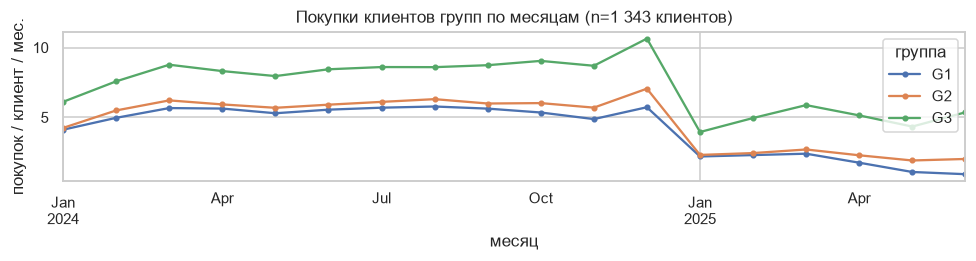


**G1 — массовый сегмент без приложения, активность сошла почти на нет (507 клиентов).** Медианный клиент делал
4.7 покупки в месяц, а в мае–июне 2025 г. — 15% от этого уровня. Падают все категории сразу:
клиент перестаёт пользоваться картой как основной. *Что предлагать:* повышенный кэшбэк на повседневные
категории (продукты, транспорт) и помощь с установкой приложения.

**G2 — массовый сегмент с приложением, падение по всем категориям (573 клиентов).** Снижение на 61%,
без учёта одежды почти такое же (62%), но без полного обнуления. Клиент доступен через
приложение. *Что предлагать:* персональные предложения в приложении на категории, где он раньше покупал.

**G3 — Зарплатный, Премиальный и Private, перестали покупать одежду и обувь по карте (263 клиентов).** Покупки одежды
упали с 1.5 до 0.17 в месяц, а остальные категории — на 19%, то есть вдвое слабее общего падения группы.
*Что предлагать:* повышенный кэшбэк и партнёрские предложения в категории «Одежда и обувь».

Каждый клиент входит ровно в одну группу. Группы не пересекаются по сегменту и наличию приложения; если бы
клиент подошёл под несколько правил, приоритет был бы G1 → G2 → G3. У 157 клиентов G1/G2 одежда тоже почти исчезла,
но для них это часть общего ухода, поэтому они остаются в G1/G2.


In [10]:
fig, ax = plt.subplots(figsize=(9, 2.5))
mon = pur[pur["client_id"].isin(camp["client_id"])].copy()
mon["group"] = mon["client_id"].map(camp.set_index("client_id")["group"])
series = (mon.groupby(["month", "group"]).size() / camp["group"].value_counts()).unstack()
series.index = series.index.to_timestamp()
series.columns = [c.split("_")[0] for c in series.columns]
series.plot(ax=ax, marker=".")
ax.set(xlabel="месяц", ylabel="покупок / клиент / мес.", title=f"Покупки клиентов групп по месяцам (n={n(len(camp))} клиентов)")
ax.legend(title="группа"); plt.tight_layout(); plt.show()
g = gsum
display(Markdown(f'''
**G1 — массовый сегмент без приложения, активность сошла почти на нет ({g.loc["G1_mass_noapp_fadeout","n"]} клиентов).** Медианный клиент делал
{g.loc["G1_mass_noapp_fadeout","rb"]:.1f} покупки в месяц, а в мае–июне 2025 г. — {g.loc["G1_mass_noapp_fadeout","last2"]*100:.0f}% от этого уровня. Падают все категории сразу:
клиент перестаёт пользоваться картой как основной. *Что предлагать:* повышенный кэшбэк на повседневные
категории (продукты, транспорт) и помощь с установкой приложения.

**G2 — массовый сегмент с приложением, падение по всем категориям ({g.loc["G2_mass_app_broad_drop","n"]} клиентов).** Снижение на {abs(g.loc["G2_mass_app_broad_drop","chg"])*100:.0f}%,
без учёта одежды почти такое же ({abs(g.loc["G2_mass_app_broad_drop","chg_oth"])*100:.0f}%), но без полного обнуления. Клиент доступен через
приложение. *Что предлагать:* персональные предложения в приложении на категории, где он раньше покупал.

**G3 — Зарплатный, Премиальный и Private, перестали покупать одежду и обувь по карте ({g.loc["G3_nonmass_clothes_stop","n"]} клиентов).** Покупки одежды
упали с {g.loc["G3_nonmass_clothes_stop","cb"]:.1f} до {g.loc["G3_nonmass_clothes_stop","ce"]:.2f} в месяц, а остальные категории — на {abs(g.loc["G3_nonmass_clothes_stop","chg_oth"])*100:.0f}%, то есть вдвое слабее общего падения группы.
*Что предлагать:* повышенный кэшбэк и партнёрские предложения в категории «Одежда и обувь».

Каждый клиент входит ровно в одну группу. Группы не пересекаются по сегменту и наличию приложения; если бы
клиент подошёл под несколько правил, приоритет был бы G1 → G2 → G3. У {int((camp["group"].isin(["G1_mass_noapp_fadeout","G2_mass_app_broad_drop"]) & (camp["rate_eval_clothes"] <= 0.2*camp["rate_base_clothes"]) & (camp["rate_base_clothes"] >= 0.5)).sum())} клиентов G1/G2 одежда тоже почти исчезла,
но для них это часть общего ухода, поэтому они остаются в G1/G2.
'''))

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

In [12]:
ex = cm["exclusion_reason"].value_counts().drop("в кампании")
why = {
    "снижения нет или оно в пределах сезонности (> −15%)": "активность не упала; сюда же входят перешедшие с карты на телефон",
    "умеренное снижение (−15…−30%) без выраженной причины": "падение небольшое, отдельная коммуникация не окупится",
    "нет согласия на маркетинговую коммуникацию": "писать нельзя по условию",
    "нет базы: карта открыта позже сентября 2024 г.": "не с чем сравнивать",
    "падение ≤ −30%, но не подходит под правило группы": "причину по данным установить нельзя, непонятно, что предлагать",
    "противоречивые версии записи клиента": "в справочнике две версии с разным сегментом или городом",
}
t = pd.DataFrame({"кто": ex.index, "клиентов": ex.values,
                  "доля от справочника": [f"{x / len(cm):.1%}" for x in ex.values],
                  "почему не берём": [why[i] for i in ex.index]})
t.loc[len(t)] = ["нет в справочнике действующих клиентов", orph, "—", "вероятно, ушли из банка; нет признаков и согласия, это задача возврата, а не активации"]
display(t.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "9pt"}))
display(Markdown(f"Знаменатель долей — {n(len(cm))} клиентов справочника. Из клиентов с падением −30% и больше {n_noconsent_drop} не дали согласия на коммуникацию."))

кто,клиентов,доля от справочника,почему не берём
снижения нет или оно в пределах сезонности (> −15%),1950,34.4%,активность не упала; сюда же входят перешедшие с карты на телефон
умеренное снижение (−15…−30%) без выраженной причины,668,11.8%,"падение небольшое, отдельная коммуникация не окупится"
нет согласия на маркетинговую коммуникацию,641,11.3%,писать нельзя по условию
нет базы: карта открыта позже сентября 2024 г.,540,9.5%,не с чем сравнивать
"падение ≤ −30%, но не подходит под правило группы",518,9.1%,"причину по данным установить нельзя, непонятно, что предлагать"
противоречивые версии записи клиента,14,0.2%,в справочнике две версии с разным сегментом или городом
нет в справочнике действующих клиентов,326,—,"вероятно, ушли из банка; нет признаков и согласия, это задача возврата, а не активации"


Знаменатель долей — 5 674 клиентов справочника. Из клиентов с падением −30% и больше 256 не дали согласия на коммуникацию.

## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

In [13]:
city_all = v.groupby("city")["change"].median() * 100
city_mass = v[v.segment == "Массовый"].groupby("city")["change"].median() * 100
mass_share = v.groupby("city")["segment"].apply(lambda s: (s == "Массовый").mean() * 100)
inc_mass = v[v.segment == "Массовый"].groupby("income_source")["change"].median() * 100
inc_all = v.groupby("income_source")["change"].median() * 100
app = v[v.has_mobile_app].copy(); app["old"] = app["app_last_login"] < "2025-01-01"
login = app.groupby(["segment", "old"])["change"].median().unstack() * 100
login_gap = (login[True] - login[False]).abs().max()
display(Markdown(f'''
* **Новосибирск падает сильнее других городов — нет.** Медиана там {city_all["Новосибирск"]:.0f}% против {city_all.drop("Новосибирск").min():.0f}…{city_all.drop("Новосибирск").max():.0f}%, но массовый сегмент составляет {mass_share["Новосибирск"]:.0f}% клиентов города (в других — {mass_share.drop("Новосибирск").min():.0f}–{mass_share.drop("Новосибирск").max():.0f}%). Внутри массового сегмента в Новосибирске {city_mass["Новосибирск"]:.0f}%, в других городах {city_mass.drop("Новосибирск").min():.0f}…{city_mass.drop("Новосибирск").max():.0f}%.
* **Падают получающие зарплату в другом банке — нет.** В целом {inc_all["Зарплата в другом банке"]:.0f}% против {inc_all["Зарплата в нашем банке"]:.0f}%, но внутри массового сегмента {inc_mass["Зарплата в другом банке"]:.0f}% против {inc_mass["Зарплата в нашем банке"]:.0f}%: разница объясняется составом сегментов.
* **Падают те, кто давно не заходил в приложение — нет.** Внутри сегментов медианы «заходил в 2025» и «последний вход в 2024» отличаются не больше чем на {login_gap:.0f} п.п., и знак разницы меняется.
* **Рост токена означает потерю карточных клиентов — нет.** Покупки через токен +{ch["Токен"]:.0f}% при пластике {ch["Карта"]:.0f}%: способ оплаты сменился, клиенты остались.
* **Сбой СБП вызвал устойчивое падение — нет.** Провал только в апреле–мае 2025 г., в июне уровень восстановился.
'''))


* **Новосибирск падает сильнее других городов — нет.** Медиана там -28% против -21…-17%, но массовый сегмент составляет 88% клиентов города (в других — 43–45%). Внутри массового сегмента в Новосибирске -33%, в других городах -45…-28%.
* **Падают получающие зарплату в другом банке — нет.** В целом -27% против -15%, но внутри массового сегмента -36% против -37%: разница объясняется составом сегментов.
* **Падают те, кто давно не заходил в приложение — нет.** Внутри сегментов медианы «заходил в 2025» и «последний вход в 2024» отличаются не больше чем на 6 п.п., и знак разницы меняется.
* **Рост токена означает потерю карточных клиентов — нет.** Покупки через токен +32% при пластике -28%: способ оплаты сменился, клиенты остались.
* **Сбой СБП вызвал устойчивое падение — нет.** Провал только в апреле–мае 2025 г., в июне уровень восстановился.


## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

In [14]:
changed = ~log["action"].str.startswith("оставлено") & ~log["action"].str.contains("тип")
s = log.loc[changed, ["field", "issue", "n_rows", "action"]].head(10)
s.columns = ["поле", "что найдено", "строк", "что сделано"]
display(s.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "8.5pt"}))
display(Markdown(f"Полный журнал — `cleaning_log.csv`, {len(log)} решений."))

поле,что найдено,строк,что сделано
branch_code,код с ведущими нулями читается как число,5729,исправлено
все поля (clients),полный дубль строки,41,удалено
client_id,один client_id — две разные версии (город/сегмент),14,"удалено (оставлена первая), клиент помечен id_conflict"
все поля (transactions),полный дубль строки,1281,удалено
txn_id,один txn_id в двух копиях: с временем и только с датой,219,удалено (оставлена копия со временем)
monthly_income,код пропуска -999,54,заменено на NaN
monthly_income,доход указан в тысячах рублей,157,исправлено (×1000)
txn_datetime,операции вне периода данных,81,удалено


Полный журнал — `cleaning_log.csv`, 16 решений.

### 8.2. Методика

* **Покупка:** `status = «успешно»`, клиент есть в справочнике, дата 01.01.2024–30.06.2025, любой канал и валюта.
* **Экспозиция:** месяцы с `max(card_open_date, начало окна)` до конца окна, месяц = 30,44 дня. До открытия текущей карты операций нет ни у одного клиента.
* `rate_base` = покупок за 2024 г. / экспозиция в 2024 г. (только при экспозиции ≥ 3 мес.); `rate_eval` = покупок за 01–06.2025 / экспозиция в 2025 г.
* `change = rate_eval / rate_base − 1`; аналогично отдельно для «Одежды и обуви» и всех остальных категорий; `last2_to_base` = (покупок за май–июнь 2025 / 2) / `rate_base`.
* **Кандидаты:** есть согласие на маркетинг, нет конфликта версий записи, экспозиция в 2024 г. ≥ 3 мес., `rate_base > 0`.
* **G1:** Массовый, нет приложения, `change ≤ −0,30` и `last2_to_base ≤ 0,5`. **G2:** Массовый, есть приложение, `change ≤ −0,30` и `change` без одежды `≤ −0,30`. **G3:** не Массовый, `rate_base` одежды ≥ 0,5, `rate_eval` одежды ≤ 0,2 × `rate_base` одежды, `change ≤ −0,15`. Приоритет G1 → G2 → G3; при превышении бюджета отбор по убыванию `rate_base − rate_eval` (не понадобился).
* **Порог −30%:** в несколько раз больше сезонного эффекта (среднемесячное за январь–июнь 2024 к среднемесячному за 2024 г.). Для G3 −15%, потому что причина ограничена одной категорией.
* **Меры:** центр — медиана, разброс — IQR (распределения скошены). Для порядковой `satisfaction_score` среднее не используется.